# CMCSACapsNet: A Novel Deep Learning Framework for Multi-Crop Health Monitoring Using Soil Nutrients and Chaotic Swarm Optimization

## Load Dataset

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv('Plant_soil_nutrients.csv')
print(df.head())
print(df.info())
print(df['Label'].value_counts())

                  Created_at  Entry_id  Humidity (%RH)  Temperature (°C)  \
0  2025-05-01T04:16:18+00:00         1            16.8              22.8   
1  2025-05-01T04:16:41+00:00         2            16.7              22.1   
2  2025-05-01T04:17:03+00:00         3            16.5              21.8   
3  2025-05-01T04:17:25+00:00         4            16.6              21.7   
4  2025-05-01T04:17:46+00:00         5            16.4              21.3   

   Conductivity (us/cm)    Ph  Nitrogen (mg/kg)  Phosphorus (mg/kg)  \
0                  1447  7.81                99                 138   
1                  1316  7.34                97                 135   
2                  1303  7.34                94                 130   
3                  1303  7.34                94                 131   
4                  1358  7.40                96                 133   

   Potassium (mg/kg) Crop_Type Label  
0                283      Bean  Poor  
1                268      Bean  Poor  

## Preprocessing

In [2]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from tensorflow.keras.utils import to_categorical
import numpy as np

df.dropna(inplace=True)
label_encoder = LabelEncoder()
df['Crop_Type'] = label_encoder.fit_transform(df['Crop_Type'])

X = df.drop(['Label', 'Created_at', 'Entry_id'], axis=1).values
y = df['Label'].values

le = LabelEncoder()
y_encoded = le.fit_transform(y)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = X_scaled.reshape(X_scaled.shape[0], X_scaled.shape[1], 1)
for i, label in enumerate(le.classes_):
    print(f"{label} --> {i}")

Healthy --> 0
Moderate --> 1
Poor --> 2


## Data Splitting

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((25466, 8, 1), (6367, 8, 1), (25466,), (6367,))

## Feature Extraction (CMAE)

In [4]:
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
def crop_aware_multiscale_attention_encoder(input_shape):
    input_layer = Input(shape=input_shape)

    # ------------------------------
    # 1. Multiscale Convolution Paths
    # ------------------------------
    conv_3 = layers.Conv1D(64, kernel_size=3, padding='same', activation='relu')(input_layer)
    conv_5 = layers.Conv1D(64, kernel_size=5, padding='same', activation='relu')(input_layer)
    conv_7 = layers.Conv1D(64, kernel_size=7, padding='same', activation='relu')(input_layer)

    # Concatenate multiscale features
    multiscale_features = layers.Concatenate()([conv_3, conv_5, conv_7])

    # ------------------------------
    # 2. Channel Attention Module (Squeeze-and-Excite)
    # ------------------------------
    gap = layers.GlobalAveragePooling1D()(multiscale_features)
    dense1 = layers.Dense(64, activation='relu')(gap)
    channel_attention = layers.Dense(multiscale_features.shape[-1], activation='sigmoid')(dense1)
    channel_attention = layers.Reshape((1, multiscale_features.shape[-1]))(channel_attention)
    multiscale_features = layers.Multiply()([multiscale_features, channel_attention])

    # ------------------------------
    # 3. Spatial Attention Module
    # ------------------------------
    spatial_avg = layers.Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(multiscale_features)
    spatial_max = layers.Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True))(multiscale_features)
    spatial_concat = layers.Concatenate(axis=-1)([spatial_avg, spatial_max])
    spatial_attention = layers.Conv1D(filters=1, kernel_size=7, padding='same', activation='sigmoid')(spatial_concat)
    multiscale_features = layers.Multiply()([multiscale_features, spatial_attention])

    # ------------------------------
    # 4. Output Feature Representation
    # ------------------------------
    output = layers.GlobalAveragePooling1D()(multiscale_features)

    return Model(inputs=input_layer, outputs=output, name="CMAE")

input_shape = X_train.shape[1:]  

cmae = crop_aware_multiscale_attention_encoder(input_shape)
cmae.summary()

X_train_cmae = cmae.predict(X_train)
X_test_cmae = cmae.predict(X_test)

print(f"Feature Shape  : {X_train_cmae.shape[1]}")

Model: "CMAE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 8, 1)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d (Conv1D)               │ (None, 8, 64)             │             256 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_1 (Conv1D)             │ (None, 8, 64)             │             384 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_2 (Conv1D)             │ (None, 8, 64)             │             512 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 8, 192)            │               0 │ conv1d[0][0],              │
│                               │                           │                 │ conv1d_1[0][0],            │
│                               │                           │                 │ conv1d_2[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling1d      │ (None, 192)               │               0 │ concatenate[0][0]          │
│ (GlobalAveragePooling1D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 64)                │          12,352 │ global_average_pooling1d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 192)               │          12,480 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape (Reshape)             │ (None, 1, 192)            │               0 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply (Multiply)           │ (None, 8, 192)            │               0 │ concatenate[0][0],         │
│                               │                           │                 │ reshape[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda (Lambda)               │ (None, 8, 1)              │               0 │ multiply[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda_1 (Lambda)             │ (None, 8, 1)              │               0 │ multiply[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate_1 (Concatenate)   │ (None, 8, 2)              │               0 │ lambda[0][0],              │
│                               │                           │                 │ lambda_1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_3 (Conv1D)             │ (None, 8, 1)              │              15 │ concatenate_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply_1 (Multiply)         │ (None, 8, 192)            │               

 Total params: 25,999 (101.56 KB)

 Trainable params: 25,999 (101.56 KB)

 Non-trainable params: 0 (0.00 B)

796/796 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step    
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Feature Shape  : 192


## Model Training

### Proposed (SADACapsNet)

Model: "SADACapsNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 192, 1)            │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_4 (Conv1D)             │ (None, 192, 64)           │             256 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 192, 64)           │             256 │ conv1d_4[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling1d_2    │ (None, 64)                │               0 │ batch_normalization[0][0]  │
│ (GlobalAveragePooling1D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 8)                 │             520 │ global_average_pooling1d_… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_3 (Dense)               │ (None, 64)                │             576 │ dense_2[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_1 (Reshape)           │ (None, 1, 64)             │               0 │ dense_3[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply_2 (Multiply)         │ (None, 192, 64)           │               0 │ batch_normalization[0][0], │
│                               │                           │                 │ reshape_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda_2 (Lambda)             │ (None, 192, 1)            │               0 │ multiply_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda_3 (Lambda)             │ (None, 192, 1)            │               0 │ multiply_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate_2 (Concatenate)   │ (None, 192, 2)            │               0 │ lambda_2[0][0],            │
│                               │                           │                 │ lambda_3[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_5 (Conv1D)             │ (None, 192, 1)            │              15 │ concatenate_2[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply_3 (Multiply)         │ (None, 192, 64)           │               0 │ multiply_2[0][0],          │
│                               │                           │                 │ conv1d_5[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_6 (Conv1D)             │ (None, 192, 64)           │          12,352 │ multiply_3[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_2 (Reshape)           │ (None, 192, 64)           │               

 Total params: 603,799 (2.30 MB)

 Trainable params: 603,671 (2.30 MB)

 Non-trainable params: 128 (512.00 B)

Proposed
Accuracy: 0.9746
Specificity: 0.9871
Precision: 0.9745
Recall: 0.9746
F1-Score: 0.9746
NPV: 0.9871
G-Mean: 0.9808
MCC: 0.9618
FPR: 0.0129
FNR: 0.0254


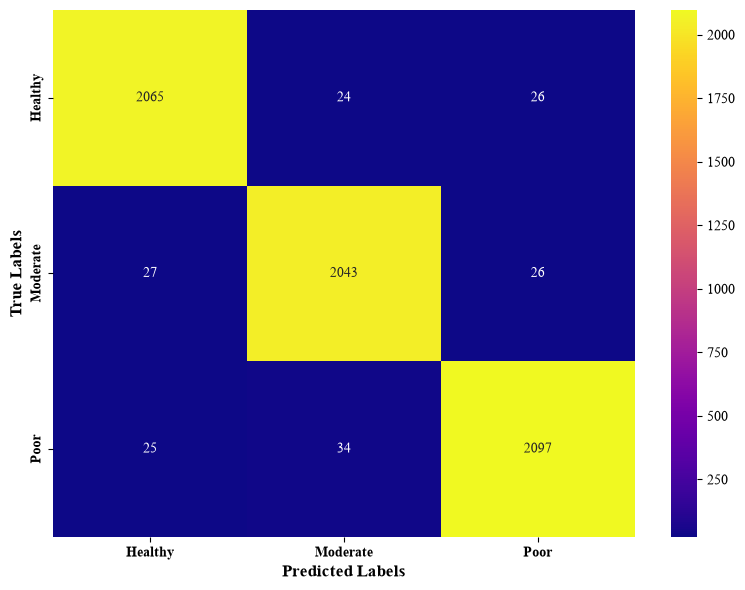

AttributeError: module 'matplotlib.cm' has no attribute 'get_cmap'

<Figure size 800x600 with 0 Axes>

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models, initializers
import random
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Lambda
from tensorflow.keras.optimizers import Adam
import pickle
import os
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, matthews_corrcoef

def logistic_map(x, r=4):
    return r * x * (1 - x)

def CGGJO(pop_size, dim, max_iter, bounds, fitness_func):
    # Initialize population
    population = np.random.rand(pop_size, dim)
    for d in range(dim):
        min_b, max_b = bounds[d]
        population[:, d] = min_b + population[:, d] * (max_b - min_b)

    # Chaotic initialization
    chaotic_seq = np.zeros(max_iter)
    chaotic_seq[0] = np.random.rand()
    for t in range(1, max_iter):
        chaotic_seq[t] = logistic_map(chaotic_seq[t-1])

    # Fitness
    fitness = np.array([fitness_func(ind) for ind in population])
    best_idx = np.argmin(fitness)
    best_sol = population[best_idx].copy()
    best_fit = fitness[best_idx]

    for t in range(max_iter):
        C = chaotic_seq[t]
        for i in range(pop_size):
            r1 = random.random()
            r2 = random.random()
            A = 2 * C * r1 - C
            D = abs(r2 * best_sol - population[i])
            population[i] = best_sol - A * D
            # Boundary control
            for d in range(dim):
                min_b, max_b = bounds[d]
                population[i, d] = np.clip(population[i, d], min_b, max_b)

        # Evaluate
        fitness = np.array([fitness_func(ind) for ind in population])
        best_idx = np.argmin(fitness)
        if fitness[best_idx] < best_fit:
            best_sol = population[best_idx].copy()
            best_fit = fitness[best_idx]

    return best_sol, best_fit


# Capsule Layer
class CapsuleLayer(layers.Layer):
    def __init__(self, num_capsules, dim_capsule, routing_iters=3, **kwargs):
        super(CapsuleLayer, self).__init__(**kwargs)
        self.num_capsules = num_capsules
        self.dim_capsule = dim_capsule
        self.routing_iters = routing_iters

    def build(self, input_shape):
        self.input_num_capsules = input_shape[1]
        self.input_dim_capsule = input_shape[2]
        self.W = self.add_weight(shape=[self.input_num_capsules, self.num_capsules,
                                        self.input_dim_capsule, self.dim_capsule],
                                 initializer='glorot_uniform',
                                 trainable=True)

    def call(self, inputs):
        inputs_expand = tf.expand_dims(inputs, 2)
        inputs_expand = tf.expand_dims(inputs_expand, -1)
        inputs_tiled = tf.tile(inputs_expand, [1, 1, self.num_capsules, 1, 1])

        u_hat = tf.matmul(self.W, inputs_tiled, transpose_a=True)
        u_hat = tf.squeeze(u_hat, axis=-1)

        b = tf.zeros_like(u_hat[..., 0])
        for _ in range(self.routing_iters):
            c = tf.nn.softmax(b, axis=2)
            s = tf.reduce_sum(c[..., tf.newaxis] * u_hat, axis=1)
            v = self.squash(s)
            b += tf.reduce_sum(u_hat * v[:, tf.newaxis, :, :], axis=-1)

        return v

    def squash(self, s):
        s_norm = tf.norm(s, axis=-1, keepdims=True)
        scale = s_norm ** 2 / (1 + s_norm ** 2) / (s_norm + tf.keras.backend.epsilon())
        return scale * s


def dual_attention_block(x):
    # Channel Attention
    avg_pool = layers.GlobalAveragePooling1D()(x)
    dense_1 = layers.Dense(x.shape[-1] // 8, activation='relu')(avg_pool)
    dense_2 = layers.Dense(x.shape[-1], activation='sigmoid')(dense_1)
    scale = layers.Reshape((1, x.shape[-1]))(dense_2)
    channel_refined = layers.Multiply()([x, scale])  # same shape as x

    # Spatial Attention (corrected with Lambda)
    avg_pool_spatial = Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(channel_refined)
    max_pool_spatial = Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True))(channel_refined)
    concat = layers.Concatenate(axis=-1)([avg_pool_spatial, max_pool_spatial])
    spatial_attention = layers.Conv1D(filters=1, kernel_size=7, padding='same', activation='sigmoid')(concat)
    spatial_refined = layers.Multiply()([channel_refined, spatial_attention])

    return spatial_refined

# Final SADACapsNet Model
def build_sadacapsnet(input_shape, num_classes):
    inputs = layers.Input(shape=input_shape)

    # Feature extraction
    x = layers.Conv1D(64, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)

    # Dual Attention
    x = dual_attention_block(x)

    # Primary Capsules
    x = layers.Conv1D(filters=64, kernel_size=3, strides=1, padding='same', activation='relu')(x)
    x = layers.Reshape((x.shape[1], x.shape[2]))(x)  # Treat each time step as a capsule

    # Capsule Layer (Final Capsules)
    capsules = CapsuleLayer(num_capsules=num_classes, dim_capsule=16, routing_iters=3)(x)

    # Output Layer (Length of Capsule Vectors)
    output_caps = Lambda(lambda z: tf.norm(z, axis=-1))(capsules)

    model = models.Model(inputs=inputs, outputs=output_caps, name='SADACapsNet')
    return model

def compute_metrics(y_true, y_pred, average='macro'):
    cm = confusion_matrix(y_true, y_pred)
    TN = np.sum(np.diag(cm)) - np.diag(cm)  # Element-wise subtract diagonal from sum
    FP = cm.sum(axis=0) - np.diag(cm)
    FN = cm.sum(axis=1) - np.diag(cm)
    TP = np.diag(cm)

    # Avoid division by zero
    epsilon = 1e-7

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average=average, zero_division=0)
    recall = recall_score(y_true, y_pred, average=average, zero_division=0)
    f1 = f1_score(y_true, y_pred, average=average, zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)

    specificity = np.mean((TN / (TN + FP + epsilon)))
    fpr = np.mean(FP / (FP + TN + epsilon))
    fnr = np.mean(FN / (FN + TP + epsilon))
    npv = np.mean((TN / (TN + FN + epsilon)))
    gmean = np.sqrt(recall * specificity)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"NPV: {npv:.4f}")
    print(f"G-Mean: {gmean:.4f}")
    print(f"MCC: {mcc:.4f}")
    print(f"FPR: {fpr:.4f}")
    print(f"FNR: {fnr:.4f}")

bounds = [(16, 128), (2, 7), (0.0001, 0.01) ]

# best_hp, best_score = CGGJO(pop_size=10, dim=3, max_iter=20, bounds=bounds, fitness_func=evaluate_model)

X_train_cmae = X_train_cmae.reshape((X_train_cmae.shape[0], X_train_cmae.shape[1], 1))
X_test_cmae = X_test_cmae.reshape((X_test_cmae.shape[0], X_test_cmae.shape[1], 1))
num_classes = len(np.unique(y_train))

optimizer = Adam(learning_rate=0.0001)

model = build_sadacapsnet(input_shape=X_train_cmae.shape[1:], num_classes=num_classes)
model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

# history = model.fit(X_train_cmae, y_train, epochs=1, batch_size=64, validation_split=0.1, verbose=1)
# y_pred = model.predict(X_test_cmae)
# y_pred= np.argmax(y_pred, axis=1)
with open('y_pred_proposed.pkl', 'rb') as f:
    y_pred = pickle.load(f)
print("Proposed")    
compute_metrics(y_test,y_pred)

plt.rcParams['font.family'] = 'Times New Roman' 
class_names = ['Healthy', 'Moderate','Poor']
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='plasma', xticklabels=class_names, yticklabels=class_names)
plt.xticks(fontweight='bold',fontsize=10)
plt.yticks(fontweight='bold',fontsize=10)
plt.xlabel('Predicted Labels',fontweight='bold',fontsize=12)
plt.ylabel('True Labels',fontweight='bold',fontsize=12)
plt.tight_layout()
plt.show()

n_classes = len(class_names)
y_test_1 = label_binarize(y_test, classes=range(n_classes))  
y_score = label_binarize(y_pred, classes=range(n_classes))  
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_1[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
plt.figure(figsize=(8, 6))
cmap = plt.cm.get_cmap('nipy_spectral', n_classes)  
colors = [cmap(i) for i in range(n_classes)]
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate',fontweight='bold',fontsize=12)
plt.ylabel('True Positive Rate',fontweight='bold',fontsize=12)
plt.legend(loc='lower right')
plt.grid()
plt.tight_layout()
plt.show()


Class-wise Performance:
   Class  Precision  Recall  F1-score  Support
 Healthy     0.9754  0.9764    0.9759     2115
Moderate     0.9724  0.9747    0.9736     2096
    Poor     0.9758  0.9726    0.9742     2156

Overall Accuracy: 0.9746

Macro and Weighted Averages:
 Average  Precision  Recall  F1-score
   Macro     0.9745  0.9746    0.9746
Weighted     0.9746  0.9746    0.9746

Confusion Matrix:
                 Predicted Healthy  Predicted Moderate  Predicted Poor
Actual Healthy                2065                  24              26
Actual Moderate                 27                2043              26
Actual Poor                     25                  34            2097


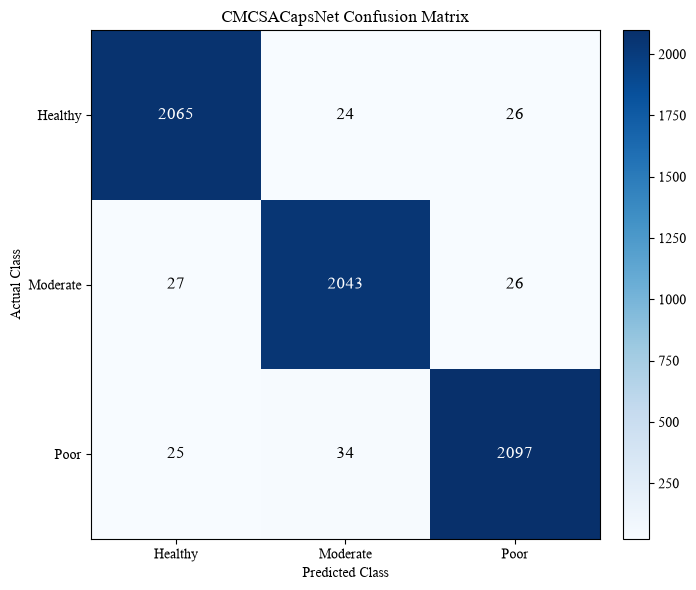

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

# --------------------------------------------------
# y_test: ground-truth test labels
# y_pred: predicted test labels
# LabelEncoder mapping:
# 0 = Healthy, 1 = Moderate, 2 = Poor
# --------------------------------------------------

class_names = ["Healthy", "Moderate", "Poor"]
class_ids = [0, 1, 2]

y_true = np.asarray(y_test).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

assert len(y_true) == len(y_pred), \
    "Ground-truth and predicted labels must have equal lengths."

# Classification metrics
report = classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_results = pd.DataFrame({
    "Class": class_names,
    "Precision": [report[c]["precision"] for c in class_names],
    "Recall": [report[c]["recall"] for c in class_names],
    "F1-score": [report[c]["f1-score"] for c in class_names],
    "Support": [int(report[c]["support"]) for c in class_names]
})

print("\nClass-wise Performance:")
print(class_results.round(4).to_string(index=False))

print("\nOverall Accuracy:",
      round(accuracy_score(y_true, y_pred), 4))

print("\nMacro and Weighted Averages:")
print(pd.DataFrame({
    "Average": ["Macro", "Weighted"],
    "Precision": [
        report["macro avg"]["precision"],
        report["weighted avg"]["precision"]
    ],
    "Recall": [
        report["macro avg"]["recall"],
        report["weighted avg"]["recall"]
    ],
    "F1-score": [
        report["macro avg"]["f1-score"],
        report["weighted avg"]["f1-score"]
    ]
}).round(4).to_string(index=False))

# Save metrics
class_results.to_csv(
    "CMCSACapsNet_Classwise_Metrics.csv", index=False
)

# --------------------------------------------------
# Confusion matrix
# Rows = actual classes; columns = predicted classes
# --------------------------------------------------

cm = confusion_matrix(y_true, y_pred, labels=class_ids)

print("\nConfusion Matrix:")
print(pd.DataFrame(
    cm,
    index=[f"Actual {c}" for c in class_names],
    columns=[f"Predicted {c}" for c in class_names]
))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted Class",
    ylabel="Actual Class",
    title="CMCSACapsNet Confusion Matrix"
)

threshold = cm.max() / 2 if cm.size and cm.max() > 0 else 0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, f"{cm[i, j]}",
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=12
        )

plt.tight_layout()
plt.savefig(
    "CMCSACapsNet_Confusion_Matrix.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

Crop categories: ['Bean', 'Maize', 'Soybean']
Health classes: ['Healthy', 'Moderate', 'Poor']

Sample counts:
Label      Healthy  Moderate  Poor
Crop_Type                         
Maize         2471      2471  2471
Bean          2379      2378  2378
Soybean       5762      5762  5761

Percentages within each crop (%):
Label      Healthy  Moderate   Poor
Crop_Type                          
Maize        33.33     33.33  33.33
Bean         33.34     33.33  33.33
Soybean      33.34     33.34  33.33

Final distribution table:
Label      Healthy  Moderate   Poor  Total
Crop_Type                                 
Maize         2471      2471   2471   7413
Bean          2379      2378   2378   7135
Soybean       5762      5762   5761  17285
Total        10612     10611  10610  31833


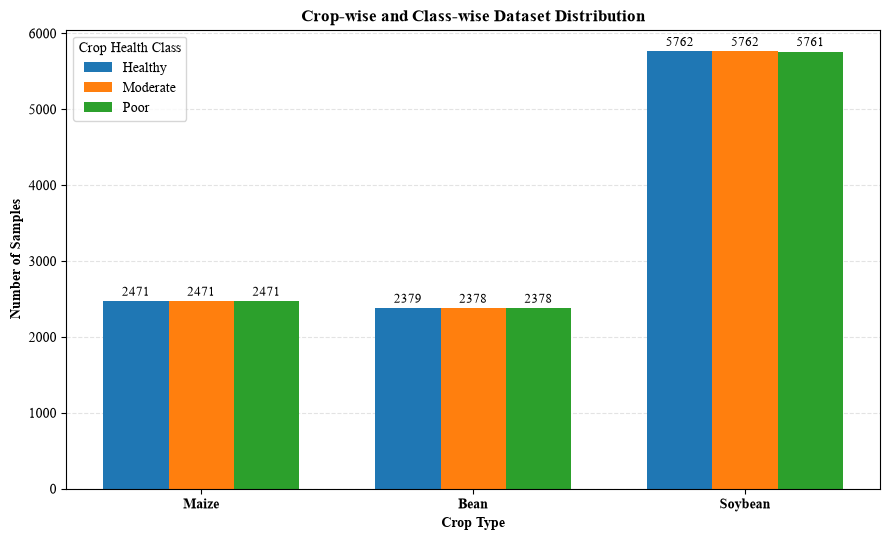

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv('Plant_soil_nutrients.csv')

# Load your dataset
# df = pd.read_csv("your_dataset.csv")

CROP_COL = "Crop_Type"
LABEL_COL = "Label"

crop_order = ["Maize", "Bean", "Soybean"]
class_order = ["Healthy", "Moderate", "Poor"]

# Standardize text labels
df[CROP_COL] = df[CROP_COL].astype(str).str.strip().str.title()
df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip().str.title()

# Check observed values before calculating
print("Crop categories:", sorted(df[CROP_COL].dropna().unique()))
print("Health classes:", sorted(df[LABEL_COL].dropna().unique()))

# Keep valid records and categories
data = df[
    df[CROP_COL].isin(crop_order) &
    df[LABEL_COL].isin(class_order)
].copy()

# Crop-wise and class-wise counts
counts = pd.crosstab(
    data[CROP_COL],
    data[LABEL_COL]
).reindex(
    index=crop_order,
    columns=class_order,
    fill_value=0
)

# Percentage of each crop's samples belonging to each class
row_percentages = (
    counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
).round(2)

# Combine counts and within-crop percentages
print("\nSample counts:")
print(counts)
print("\nPercentages within each crop (%):")
print(row_percentages)

# Add crop totals
counts["Total"] = counts.sum(axis=1)

# Total counts by class and overall
counts.loc["Total"] = counts.sum(axis=0)

print("\nFinal distribution table:")
print(counts)

# Export tables
counts.to_csv("Crop_Class_Distribution_Counts.csv")
row_percentages.to_csv("Crop_Class_Distribution_Percentages.csv")

# ---------------------------------------------------
# Grouped bar chart: class distribution per crop
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(crop_order))
width = 0.24

for i, health_class in enumerate(class_order):
    values = (
        pd.crosstab(data[CROP_COL], data[LABEL_COL])
        .reindex(index=crop_order, columns=class_order, fill_value=0)
        [health_class]
    )
    bars = ax.bar(
        x + (i - 1) * width,
        values.values,
        width,
        label=health_class
    )

    ax.bar_label(bars, padding=2, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(crop_order, fontweight="bold")
ax.set_xlabel("Crop Type", fontweight="bold")
ax.set_ylabel("Number of Samples", fontweight="bold")
ax.set_title("Crop-wise and Class-wise Dataset Distribution",
             fontweight="bold")
ax.legend(title="Crop Health Class")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "Crop_Class_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

### Simple CNN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dropout, Dense
def build_cnn(input_shape,numclasses):
    model = Sequential()
    model.add(Conv1D(64, kernel_size=3, activation='relu', input_shape=input_shape))
    model.add(Conv1D(64, kernel_size=3, activation='relu'))
    model.add(Flatten())
    model.add(Dropout(0.3))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(numclasses, activation='softmax'))
    return model

model = build_cnn(input_shape=X_train_cmae.shape[1:], numclasses=num_classes)    
model.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(),metrics=['accuracy'])
model.fit(X_train_cmae, y_train, validation_data=(X_test_cmae, y_test), epochs=1, batch_size=64)
y_pred = model.predict(X_test_cmae)
y_pred = np.argmax(y_pred, axis=1)
with open('y_pred_cnn.pkl', 'rb') as f:
    y_pred = pickle.load(f)
print("CNN")    
compute_metrics(y_test,y_pred)

### Bi-LSTM

In [ ]:
from tensorflow.keras.layers import Bidirectional, LSTM
def build_bilstm(input_shape,numclasses):
    model = Sequential()
    model.add(Bidirectional(LSTM(64, return_sequences=False), input_shape=input_shape))
    model.add(Dropout(0.3))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(numclasses, activation='softmax'))
    return model

model = build_bilstm(input_shape=X_train_cmae.shape[1:], numclasses=num_classes)    
model.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(),metrics=['accuracy'])
model.fit(X_train_cmae, y_train, validation_data=(X_test_cmae, y_test), epochs=1, batch_size=64)
y_pred = model.predict(X_test_cmae)
y_pred = np.argmax(y_pred, axis=1)
with open('y_pred_bilstm.pkl', 'rb') as f:
    y_pred = pickle.load(f)
print("Bi-LSTM")    
compute_metrics(y_test,y_pred)

### GRU

In [ ]:
from tensorflow.keras.layers import GRU
def build_gru(input_shape,numclasses):
    model = Sequential()
    model.add(GRU(64, return_sequences=False, input_shape=input_shape))
    model.add(Dropout(0.3))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(numclasses, activation='softmax'))
    return model

model = build_gru(input_shape=X_train_cmae.shape[1:], numclasses=num_classes)    
model.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(),metrics=['accuracy'])
model.fit(X_train_cmae, y_train, validation_data=(X_test_cmae, y_test), epochs=1, batch_size=64)
y_pred = model.predict(X_test_cmae)
y_pred = np.argmax(y_pred, axis=1)
with open('y_pred_gru.pkl', 'rb') as f:
    y_pred = pickle.load(f)
print("GRU")    
compute_metrics(y_test,y_pred)

### LSTM

In [ ]:
def build_lstm(input_shape,numclasses):
    model = Sequential()
    model.add(LSTM(64, return_sequences=False, input_shape=input_shape))
    model.add(Dropout(0.3))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(numclasses, activation='softmax'))
    return model

model = build_lstm(input_shape=X_train_cmae.shape[1:], numclasses=num_classes)    
model.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(),metrics=['accuracy'])
model.fit(X_train_cmae, y_train, validation_data=(X_test_cmae, y_test), epochs=1, batch_size=64)
y_pred = model.predict(X_test_cmae)
y_pred = np.argmax(y_pred, axis=1)
with open('y_pred_lstm.pkl', 'rb') as f:
    y_pred = pickle.load(f)
print("LSTM")    
compute_metrics(y_test,y_pred)